# CA3

### Imports

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

### Reading data

In [2]:
# Setting random seed
seed = 42

# Reading data
df_train = pd.read_csv("train.csv")

### Data exploration and visualisation

In [3]:
# sns.pairplot(
#     data=df_train,
#     hue='quality'
# )
# plt.show()

#### Summary

It is difficult to see a clear pattern between features and quality of wine. What I do see is that *alcohol* has a sort of grouping between good and bad wine. I can also see some grouping between good and bad for the *density* feature

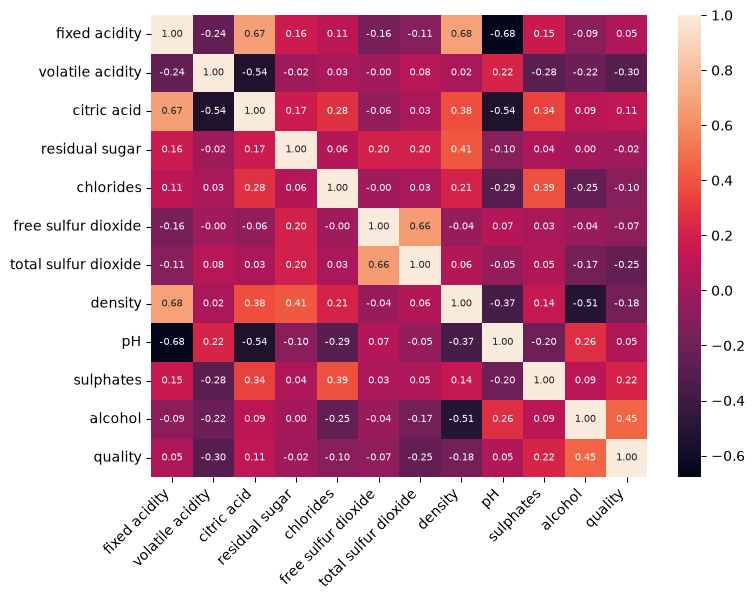

In [4]:
# Correlation between features
df_train_corr = df_train.drop(
    ['Id'],
    axis=1
).corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=df_train_corr,
    annot=True,
    annot_kws={"size":7},
    fmt=".2f"
)
plt.xticks(
    rotation=45,
    ha='right'
)
plt.show()

#### Summary

There are some features like *pH, density, citric acid* that have high correlation with many other features. I'd like to look into the importance of these features. Might be able to remove them?

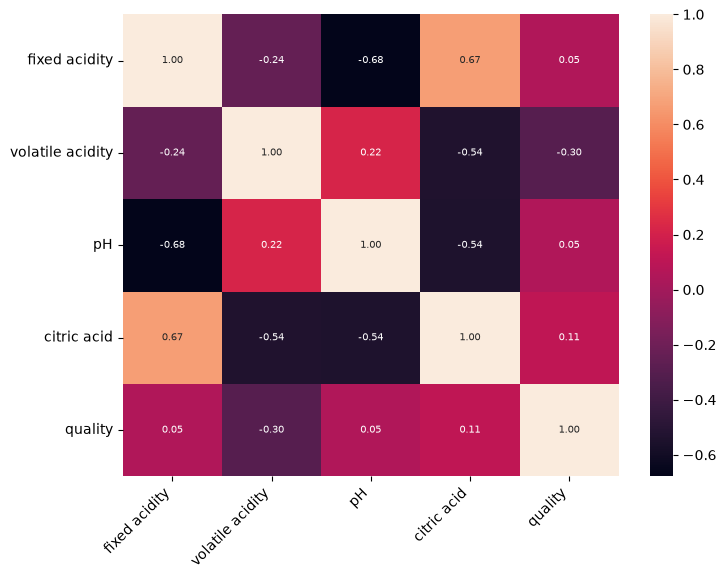

In [5]:
# Correlation between 
df_train_corr = df_train[
    [
        'fixed acidity',
        'volatile acidity',
        'pH',
        'citric acid',
        'quality'
    ]].corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=df_train_corr,
    annot=True,
    annot_kws={"size":7},
    fmt=".2f"
)

plt.xticks(
    rotation=45,
    ha='right'
)
plt.show()

#### Summary
*Citric acid* is highly correlated with all features except *quality*.

*Volatile acidity* is the most interesting one for me since it has the highest correlation with *quality* and lower correlation with other features in comparison (except for *citric acid*).
Can't disgard this feature because of the high correlation with *quality*.

*Fixed acidity* has a high correlation with *pH, citric acid* and a low correlation with *quality*. Might leave this out. 


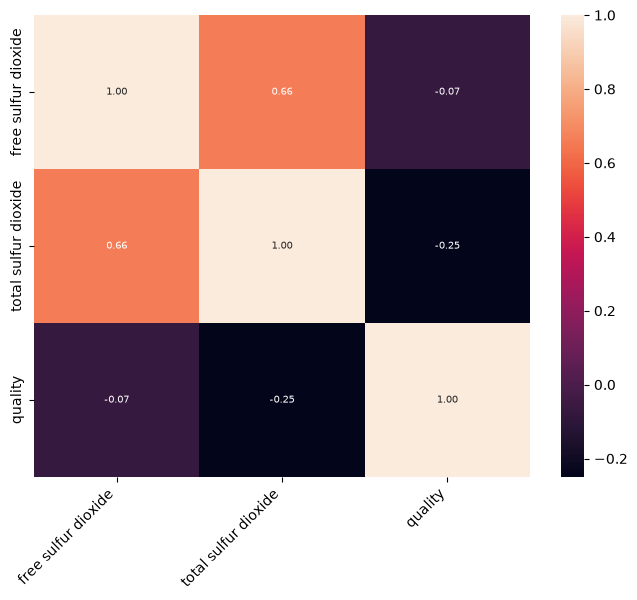

In [6]:
# Correlation between 
df_train_corr = df_train[
    [
        'free sulfur dioxide',
        'total sulfur dioxide',
        'quality'
    ]].corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=df_train_corr,
    annot=True,
    annot_kws={"size":7},
    fmt=".2f"
)
plt.xticks(
    rotation=45,
    ha='right'
)
plt.show()

#### Summary
The two features are highly correlated with each other, but *total sulfur dioxide* has a higher correlation with *quality* than *free sulfur dioxide*. Might leave only *total sulfur dioxide* for the training.

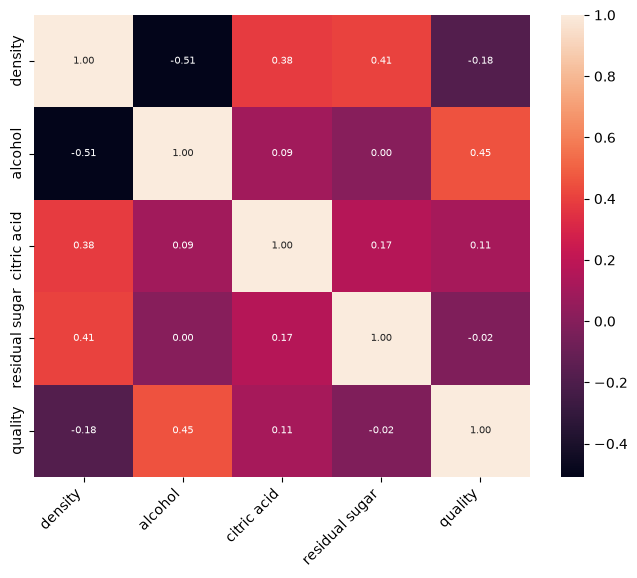

In [7]:
# Correlation between 
df_train_corr = df_train[
    [
        'density',
        'alcohol',
        'citric acid',
        'residual sugar',
        'quality'
    ]].corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=df_train_corr,
    annot=True,
    annot_kws={"size":7},
    fmt=".2f"
)
plt.xticks(
    rotation=45,
    ha='right'
)
plt.show()

#### Summary
*Alcohol* has a high correlation with *quality* and *density*.

*residual sugar* has very low correlation with quality, and might not add very much to the model building. 

### Box plots

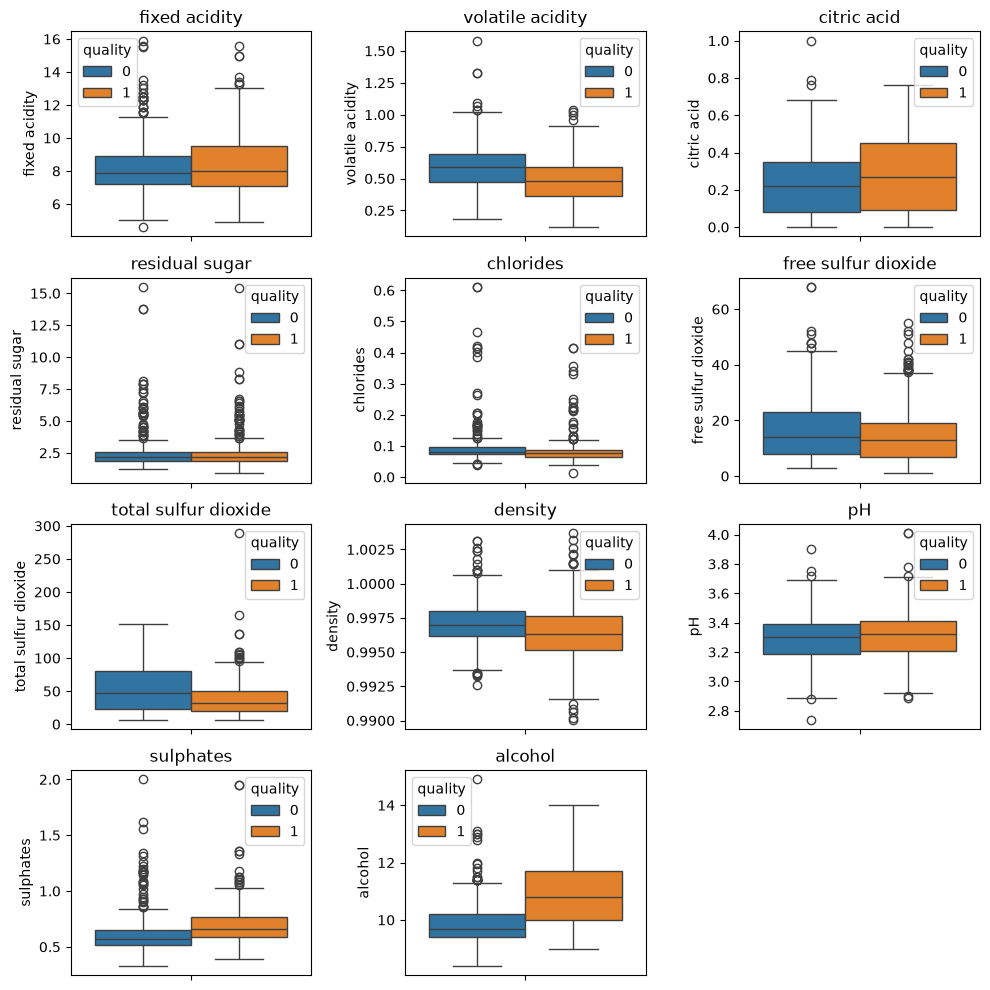

In [8]:
# Features to plot
features = df_train.select_dtypes(include=['number']).columns[:11]

fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.ravel()

# plotting for each feature
for i, feature in enumerate(features):
    sns.boxplot(
        data=df_train,
        y=feature,
        ax=axes[i],
        hue='quality'
    )
    axes[i].set_title(feature)
    
# hiding last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()

#### Summary

There are some outliers that are very far out in *total sulfur dioxide, sulphates, residual sugar*. There is a single point in *citric acid* that is a potential outlier. 

*Chlorides* looks like a bit of a mess, but it's not normally distributed so I won't do much about it. 

*Volatile acidity* could also be something to look into. 

There are some features that don't have a lot of outliers. Could be removed because they are so few? For example *alcohol, free sulfur dioxide, volatile acidity*.

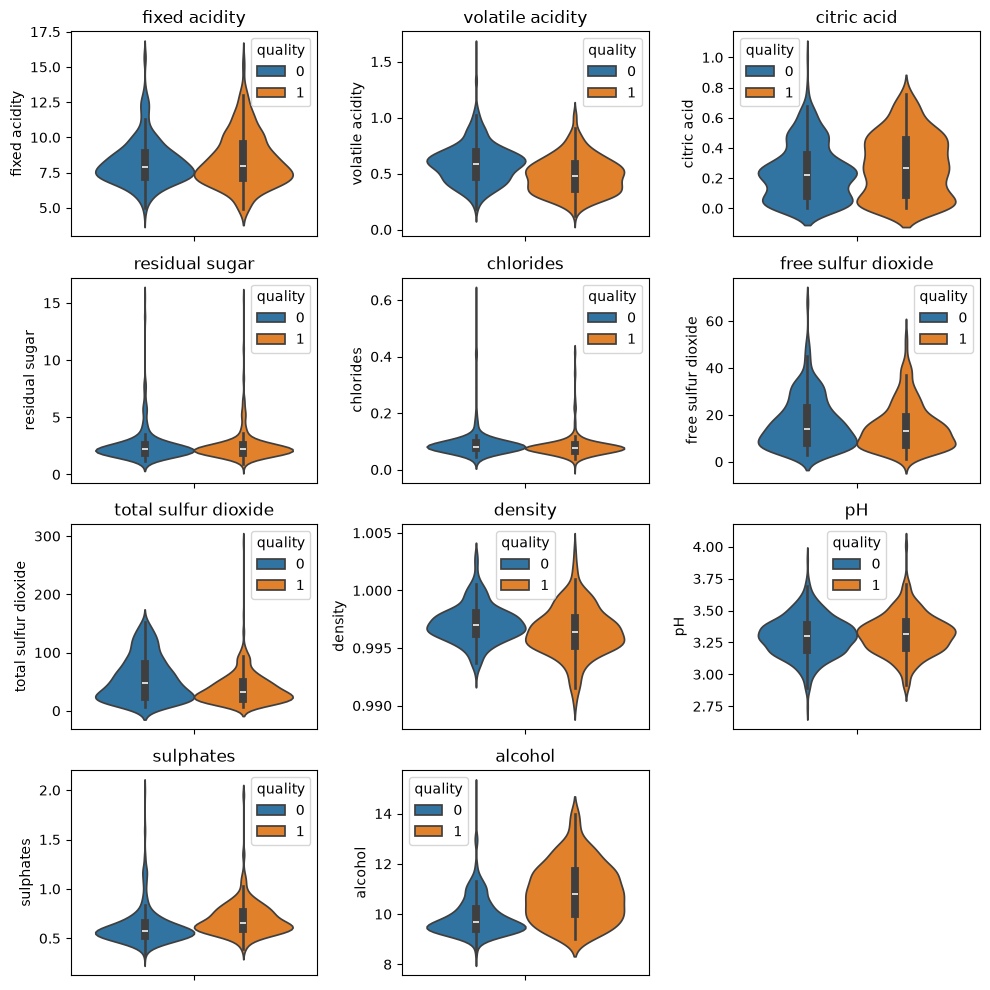

In [9]:
# Violin plot

# Features
features = df_train.columns[:11] #

fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.ravel()

# plotting for each feature
for i, feature in enumerate(features):
    sns.violinplot(data=df_train,
                   y=feature,
                   ax=axes[i],
                   hue='quality')
    axes[i].set_title(feature)
    
# hiding last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()

### Data cleaning

In [10]:
# Looking for missing values

df_train.isna().sum() # No missing values

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [11]:
# Looking for duplicated values
df_train.duplicated().sum() # Nothing duplicated

np.int64(0)

In [12]:
# What more to clean?

### Data preprocessing and visualisation

I think I will remove features *fixed acidity, pH, citric acid*, and leave only *volatile acidity* as this seems to be to be a measure of almost the same thing. The correlation heatmap also supports that decision. I am also deciding to remove *free sulfur dioxide* because this has a high correlation with *total sulfur dioxide*. Also, *total sulfur dioxide* has a higher correlation with *quality* than the *free sulfur dioxide*. 



#### Look at feature importance

In [13]:
# Ratio of free sulfur dioxide over total sulfur dioxide
df_train['ratio sulfur dioxide'] = df_train['free sulfur dioxide'] / df_train['total sulfur dioxide']

# Sum of fixed acidity and citric acid
df_train['sum acidity'] = df_train['fixed acidity'] + df_train['citric acid']

# Chemical equilibrium of SO2
df_train['molecular SO2'] = df_train['free sulfur dioxide'] / (1 + 10**((df_train['pH'] - 1.8)))

C:\Users\stige\AppData\Local\Temp\ipykernel_20184\2414861768.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance',


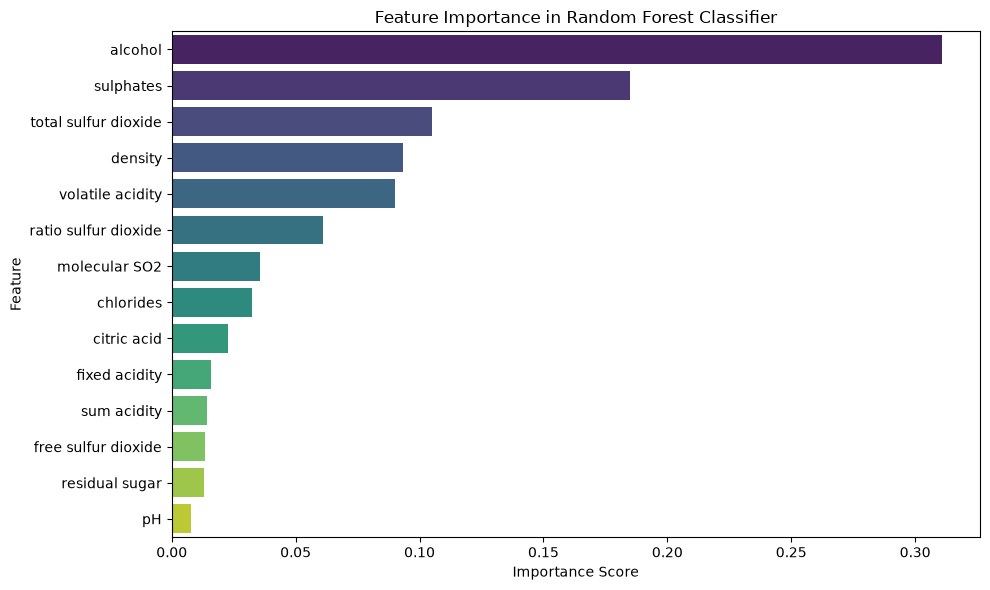

In [14]:
# Creating X and y
X = df_train.drop(['quality', 'Id'],
                  axis=1)
y = df_train['quality']

# Splitting into training and test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.25,
                                                    random_state=seed)

# Initializing a classifier
classifier = RandomForestClassifier(n_estimators=100,
                                    max_depth=5,
                                    random_state=seed,
                                    min_impurity_decrease=0.01)
classifier.fit(X_train, y_train)

# Predictions
y_pred = classifier.predict(X_test)
y_pred_train = classifier.predict(X_train)

# Getting importance values
importances = classifier.feature_importances_
feature_names = X_train.columns

# Create a DataFrame and sort by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance',
            y='Feature',
            data=feature_importance,
            palette='viridis'
)
plt.title('Feature Importance in Random Forest Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [15]:
# Removing features based on feature importance.
# Dropping the 3 bottom features.

# X = df_train.drop(['quality', 'Id', 'citric acid', 'free sulfur dioxide', 'residual sugar'], axis=1)
# y = df_train['quality']

# Result:
# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 77.10                    | 74.01                    | 72.34              | 75.68             
# 500          | 3          | 79.35                    | 75.27                    | 73.47              | 77.07             
# 500          | 4          | 81.83                    | 75.78                    | 74.01              | 77.55             
# 500          | 5          | 84.84                    | 76.29                    | 74.58              | 77.99    

In [16]:
# # Removing features based on feature importance. 
# # Leaving only the 5 top features.

# X = df_train.drop(['quality', 'Id', 'citric acid', 'free sulfur dioxide', 'residual sugar', 'fixed acidity', 'pH', 'chlorides'], axis=1)
# y = df_train['quality']

# Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 76.30                    | 73.44                    | 71.78              | 75.10             
# 500          | 3          | 78.89                    | 74.91                    | 73.19              | 76.63             
# 500          | 4          | 80.92                    | 75.96                    | 74.11              | 77.81             
# 500          | 5          | 83.44                    | 76.44                    | 74.52              | 78.36             

In [17]:
# # including every feature

# X = df_train.drop(['quality', 'Id'], axis=1)
# y = df_train['quality']

# Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 77.13                    | 73.74                    | 71.98              | 75.50             
# 500          | 3          | 79.43                    | 74.97                    | 73.24              | 76.70             
# 500          | 4          | 82.07                    | 75.87                    | 74.23              | 77.50             
# 500          | 5          | 85.66                    | 76.56                    | 74.83              | 78.28             

In [18]:
# Including features based on the highest heatmap correlations on quality (>= 0.20)

# X = df_train[['alcohol', 'sulphates', 'volatile acidity', 'total sulfur dioxide']]
# y = df_train['quality']

# Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 75.78                    | 72.81                    | 71.11              | 74.52             
# 500          | 3          | 78.46                    | 74.73                    | 72.91              | 76.55             
# 500          | 4          | 80.65                    | 75.42                    | 73.62              | 77.22             
# 500          | 5          | 83.16                    | 75.93                    | 74.13              | 77.73             

In [19]:
# Including features based on the highest heatmap correlations on quality (>= 0.10)

# X = df_train[['alcohol', 'sulphates', 'volatile acidity', 'total sulfur dioxide', 'citric acid', 'density', 'chlorides']]
# y = df_train['quality']

# Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 77.22                    | 74.10                    | 72.37              | 75.84             
# 500          | 3          | 79.21                    | 75.00                    | 73.27              | 76.73             
# 500          | 4          | 81.56                    | 75.81                    | 74.09              | 77.53             
# 500          | 5          | 84.17                    | 76.68                    | 74.95              | 78.41             

In [20]:
# Including top 2 features based on feature importance

# X = df_train[['alcohol', 'sulphates']]
# y = df_train['quality']

# Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 500          | 2          | 74.24                    | 72.87                    | 71.09              | 74.66             
# 500          | 3          | 75.07                    | 72.93                    | 71.22              | 74.65             
# 500          | 4          | 76.70                    | 72.87                    | 71.12              | 74.63             
# 500          | 5          | 79.66                    | 73.62                    | 71.61              | 75.64             

In [21]:
# # # Result:

# Mean Accuracy Table (Grouped by Hyperparameters):
# n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
# --------------------------------------------------------------------------------------------------------------
# 25           | 3          | 78.69                    | 75.20                    | 74.15              | 76.25             
# 25           | 4          | 80.74                    | 75.78                    | 74.86              | 76.69             
# 25           | 5          | 83.15                    | 75.58                    | 74.73              | 76.43             
# 100          | 3          | 78.84                    | 75.40                    | 74.54              | 76.25             
# 100          | 4          | 80.81                    | 75.96                    | 74.95              | 76.97             
# 100          | 5          | 82.99                    | 76.10                    | 75.08              | 77.11                  

### Feature engineering

In [ ]:
# Keeping features based on correlation heatmap and feature importance
X = df_train[
        [
                'alcohol',
                'sulphates',
                'density',
                'volatile acidity',
                'chlorides',
        ]
]
y = df_train['quality']

### Modelling

In [36]:
depths = [6]
num_estimators = [100]
seeds = list(range(1, 21))

# Dictionary to store accuracies per hyperparameter combination
hyperparam_accuracies = {}

# Make dictionary where key is (num_estimators, depth), value holds train/test lists of accuracies
for n_est in num_estimators:
    for depth in depths:
        hyperparam_accuracies[(n_est, depth)] = {'train': [], 'test': []}

# Loop for every seed
for seed_number in seeds:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=seed_number,
        stratify=y
    )
    
    # Loop for every number of n_estimators
    for n_est in num_estimators:
        # Loop for every max_depth value
        for depth in depths:
            # Instantiate Random forest classifier
            classifier = RandomForestClassifier(
                n_estimators=n_est,
                max_depth=depth,
                random_state=seed,
                min_impurity_decrease=0.015,
                criterion='entropy',
                n_jobs=-1,
                bootstrap=True,
                max_features='sqrt',
                min_samples_leaf=1,
                min_samples_split=10,
                
            )
            # Fit classifier
            classifier.fit(X_train, y_train)
            
            # Make predictions
            y_pred = classifier.predict(X_test)
            y_pred_train = classifier.predict(X_train)

            # Evaluate on test and train set
            accuracy_test = accuracy_score(y_test, y_pred)
            accuracy_train = accuracy_score(y_train, y_pred_train)
            
            # Store by hyperparameter combination
            hyperparam_accuracies[(n_est, depth)]['train'].append(accuracy_train)
            hyperparam_accuracies[(n_est, depth)]['test'].append(accuracy_test)

# Print mean accuracy table with 95% CI on mean test accuracy
print("\nMean Accuracy Table (Grouped by Hyperparameters):")
print(f"{'n_estimators':<12} | {'max_depth':<10} | {'Mean Train Accuracy (%)':<24} | {'Mean Test Accuracy (%)':<24} | {'95% CI Lower':<18} | {'95% CI Upper':<18}")
print("-" * 110)

# 95% confidence interval
z_score = 1.96

# Loop through every (n_est, depth) combination
for (n_est, depth) in hyperparam_accuracies.keys():
    train_accs = hyperparam_accuracies[(n_est, depth)]['train']
    test_accs = hyperparam_accuracies[(n_est, depth)]['test']
    
    # Calculate mean and standard deviation
    mean_train = np.mean(train_accs) * 100
    mean_test = np.mean(test_accs) * 100
    std_test = np.std(test_accs) * 100  # Sample standard deviation
    n = len(test_accs)
    
    # Calculate 95% confidence interval
    se = std_test / np.sqrt(n)
    margin_of_error = z_score * se
    ci_lower = mean_test - margin_of_error
    ci_upper = mean_test + margin_of_error
    
    print(f"{n_est:<12} | {depth:<10} | {mean_train:<24.2f} | {mean_test:<24.2f} | {ci_lower:<18.2f} | {ci_upper:<18.2f}")


Mean Accuracy Table (Grouped by Hyperparameters):
n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
--------------------------------------------------------------------------------------------------------------
100          | 6          | 79.74                    | 75.93                    | 74.94              | 76.92             


#### Summary

Through grid searches and several runs we found that the best hyperparameters are:
- n_estimators: 100
- max_depth: 5
- min_impurity_decrease: 0.015
- max_features: 'sqrt'
- min_samples_leaf: 1
- min_samples_split: 10
                

In [24]:
# Create pandas DataFrame for easy handling
accuracies = pd.DataFrame(hyperparam_accuracies).transpose()

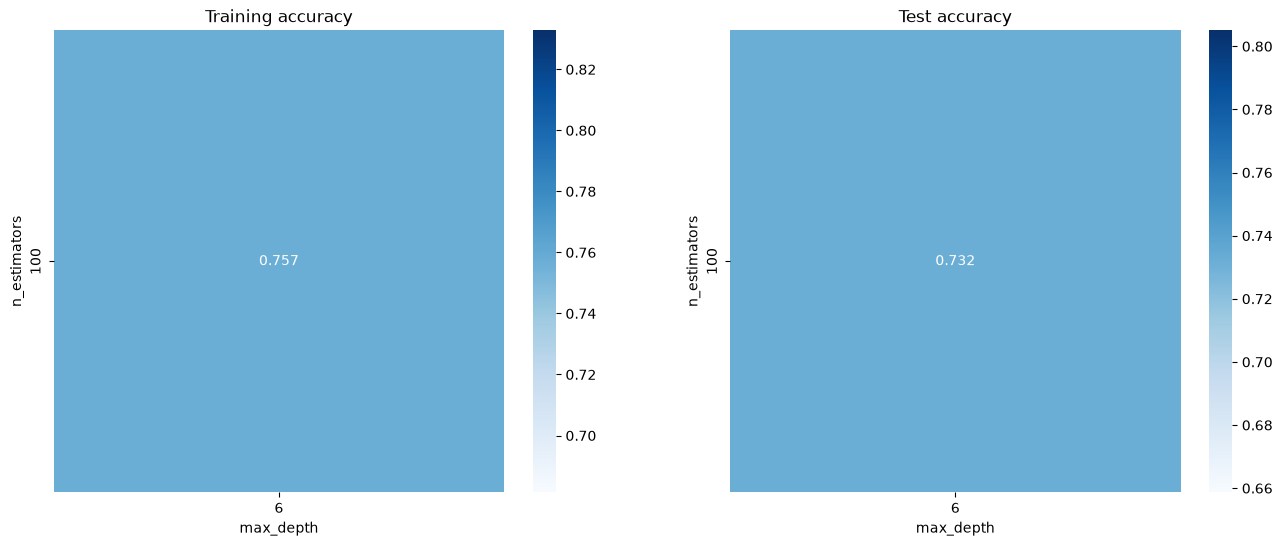

In [25]:
# Calculate mean for heat map
accuracies['train_mean'] = [np.mean(sublist) for sublist in accuracies['train']]
accuracies['test_mean'] = [np.mean(sublist) for sublist in accuracies['test']]

# Reshape flat list into 2d matrix
train_matrix = np.array(accuracies['train_mean']).reshape(len(num_estimators), len(depths))
test_matrix = np.array(accuracies['test_mean']).reshape(len(num_estimators), len(depths))

# Create figure with both heatmaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Create heatmap for train accuracies
sns.heatmap(
    train_matrix,
    xticklabels=depths,
    yticklabels=num_estimators,
    ax=ax1,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
ax1.set_title("Training accuracy")
ax1.set_xlabel("max_depth")
ax1.set_ylabel("n_estimators")

# Create heatmap for test accuracies
sns.heatmap(
    test_matrix,
    xticklabels=depths,
    yticklabels=num_estimators,
    ax=ax2,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
ax2.set_title("Test accuracy")
ax2.set_xlabel("max_depth")
ax2.set_ylabel("n_estimators")
plt.show()

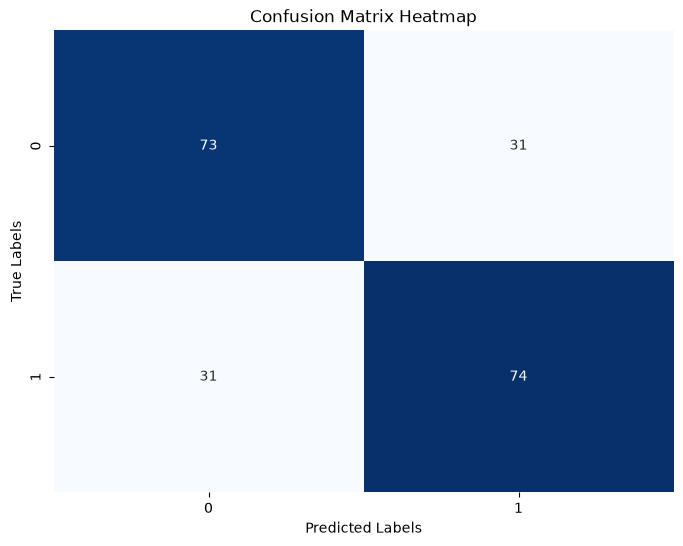

In [26]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False
            )

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

#### Summary

The confusion matrix shows that there are many missclassifications.

### Final evaluation

In [27]:
classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=seed,
    min_impurity_decrease=0.015,
    criterion='entropy',
    n_jobs=-1,
    bootstrap=True,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=10
)

classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.015
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samp

### Kaggle submission

In [28]:
# Read data
df_test = pd.read_csv("test.csv")

In [29]:
X = df_test[
        [
                'alcohol',
                'sulphates',
                'total sulfur dioxide',
                'volatile acidity',
                'density',
                'chlorides'
        ]
]

In [30]:
# Make predictions
y_final = classifier.predict(X)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- total sulfur dioxide
- volatile acidity


In [ ]:
# Create submission file
y_test = pd.DataFrame(y_final, columns=['quality'])
y_test.index.name = "Id"
y_test[['quality']].to_csv("submission.csv")